# TP2 - Reconstrucción 3D
**I308 Visión Artificial - Universidad de San Andrés**

En este notebook recorremos el pipeline paso a paso y comentamos qué sale en cada etapa.
El código de cada paso vive en `pipeline/` (son las mismas funciones que usa
`python pipeline/run_pipeline.py configs/<dataset>.yaml`); acá solo las llamamos y
miramos los resultados.

1. Calibración y rectificación estéreo
2. Disparidad y nube local (una captura en detalle)
3. Pose con el objeto de referencia (ChArUco) y paso al sistema del mundo
4. Reconstrucción de todas las capturas
5. Fusión y optimización en Open3D
6. Malla con Poisson (opcional)
7. Medición métrica

## 0. Preparación

Antes de empezar, dejamos todo listo para que el notebook encuentre nuestras funciones:
nos paramos en la carpeta del proyecto y agregamos `pipeline/` al path de Python,
que es donde está el código de cada etapa.

In [1]:
import os
import sys

# Si el notebook se abre desde otra carpeta, subimos hasta la raíz del proyecto
# (la que tiene la carpeta pipeline/), así las rutas relativas como configs/grupo.yaml funcionan.
while not os.path.isdir("pipeline") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")

sys.path.insert(0, os.path.abspath("pipeline"))

# Algunas celdas cambian de comportamiento en Colab (por ejemplo, usan SGBM en vez de CREStereo).
# Colab carga google.colab al arrancar, así que alcanza con ver si ya está importado.
COLAB = "google.colab" in sys.modules

print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: c:\Users\pepob\OneDrive\Documentos\Facu\Vision Artificial\tp2_reconstruccion_3d


In [2]:
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
import yaml
from IPython.display import Image, display

import calibration
import fusion
import pose
import run_pipeline
import stereo
from dataset import list_stereo_pairs, read_markers_yaml

# onnxruntime avisa que no encuentra GPU (CUDA) y sigue con la CPU: es esperable, no hace falta verlo.
warnings.filterwarnings("ignore", message="Specified provider 'CUDAExecutionProvider'")

print("OpenCV", cv2.__version__, "| Open3D", o3d.__version__, "| NumPy", np.__version__)


def show_image(path, width=1000):
    """Muestra una figura que el pipeline guardó en disco."""
    display(Image(filename=path, width=width))


def plot_cloud(points, colors, title, max_points=40_000, elev=25, azim=-60):
    """Dibuja una nube de puntos con matplotlib. Si tiene muchos puntos, toma una muestra al azar."""
    if len(points) > max_points:
        sample = np.random.default_rng(0).choice(len(points), max_points, replace=False)
        points, colors = points[sample], colors[sample]
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], c=colors, s=0.3)
    ax.set_box_aspect(np.ptp(points, axis=0))
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("X [mm]"); ax.set_ylabel("Y [mm]"); ax.set_zlabel("Z [mm]")
    ax.set_title(title)
    plt.show()

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
OpenCV 4.13.0 | Open3D 0.20.0 | NumPy 2.4.6


### Configuración

Cada dataset tiene su `.yaml` en `configs/` con todo lo que se puede ajustar: la caja que
encierra al objeto, los parámetros de disparidad, los filtros, etc. `configs/grupo.yaml` es
nuestro dataset: un peluche apoyado sobre un ChArUco de 9x13.

**Disparidad**: en nuestra config usamos **CREStereo** (una red neuronal). En CPU tarda unos
15 s por par, o sea ~15 min para las 58 capturas, pero las disparidades quedan guardadas en
`intermediate/` y las corridas siguientes son rápidas. En Colab usamos **SGBM** por defecto
(tarda segundos), salvo que se ponga `USE_CRESTEREO = True`.

In [3]:
CONFIG_PATH = "configs/grupo.yaml"
USE_CRESTEREO = None   # None: lo que diga la config (en Colab, SGBM). True / False para forzarlo.

with open(CONFIG_PATH, encoding="utf-8") as f:
    config = yaml.safe_load(f)

if USE_CRESTEREO is None:
    USE_CRESTEREO = config.get("disparity_method") == "crestereo" and not COLAB
config["disparity_method"] = "crestereo" if USE_CRESTEREO else "sgbm"

# Con SGBM guardamos en otra carpeta para no pisar los resultados de CREStereo.
if not USE_CRESTEREO and config["output"] == "output/grupo":
    config["output"] = "output/grupo_sgbm"

# El modelo de CREStereo se descarga solo la primera vez.
if USE_CRESTEREO:
    model_path = os.path.join(config["crestereo"]["models_dir"], "crestereo_combined_iter10_720x1280.onnx")
    if not os.path.exists(model_path):
        os.makedirs(os.path.dirname(model_path), exist_ok=True)
        !curl -sL -o {model_path} https://github.com/nburrus/stereodemo/releases/download/v0.1-crestereo/crestereo_combined_iter10_720x1280.onnx

dataset_dir = run_pipeline.resolve(config["dataset"])
output_dir = run_pipeline.resolve(config["output"])
figures_dir = os.path.join(output_dir, "figures")
cache_dir = os.path.join(output_dir, "intermediate")   # disparidades ya calculadas
for folder in (output_dir, figures_dir, cache_dir):
    os.makedirs(folder, exist_ok=True)

print("Dataset:   ", dataset_dir)
print("Resultados:", output_dir)
print("Disparidad:", run_pipeline.method_name(config))

Dataset:    c:\Users\pepob\OneDrive\Documentos\Facu\Vision Artificial\tp2_reconstruccion_3d\tp2_reconstruccion_3d/datasets
Resultados: c:\Users\pepob\OneDrive\Documentos\Facu\Vision Artificial\tp2_reconstruccion_3d\output/grupo
Disparidad: CREStereo


## 1. Calibración y rectificación estéreo

- En cada par de `calib/` buscamos las esquinas del checkerboard (`findChessboardCorners` +
  `cornerSubPix`).
- `stereoCalibrateExtended` estima los intrínsecos de cada cámara (K y distorsión) y cómo está
  ubicada una cámara respecto de la otra (rotación R y traslación T). También devuelve el error
  de reproyección de cada par.
- Con ese error por par descartamos las fotos que calibraron mal (más de 2 px, ver
  `max_view_error_px` en la config) y volvemos a calibrar sin ellas.
- `stereoRectify` + `initUndistortRectifyMap` calculan los mapas que, aplicados con `remap`,
  dejan las líneas epipolares horizontales.

In [4]:
stereo_params, rectify_maps = run_pipeline.step_calibration(config, dataset_dir, output_dir, figures_dir)


[4.1] Calibración y rectificación estéreo
  checkerboard (9, 6), cuadrado 28.0 mm
  checkerboard detectado en 81 pares
  RMS estéreo: 1.074px
  se descartan 5 pares con error > 2.0 px: [4, 36, 43, 48, 51]
  RMS estéreo: 0.711px
  left_K = np.array([
	[   606.180,	     0.000,	   950.852],
	[     0.000,	   603.398,	   540.291],
	[     0.000,	     0.000,	     1.000]
])
  left_dist = np.array([
	[  0.017757,	 -0.032252,	 -0.000040,	  0.000084,	  0.005629]
])
  right_K = np.array([
	[   607.236,	     0.000,	   947.013],
	[     0.000,	   604.850,	   528.970],
	[     0.000,	     0.000,	     1.000]
])
  right_dist = np.array([
	[  0.019245,	 -0.032664,	 -0.000011,	 -0.000051,	  0.005704]
])
  R = np.array([
	[     1.000,	    -0.001,	     0.017],
	[     0.001,	     1.000,	    -0.003],
	[    -0.017,	     0.003,	     1.000]
])
  T = np.array([
	[-60.126224],
	[ -0.069887],
	[ -0.250199]
])
  baseline = 60.13 mm


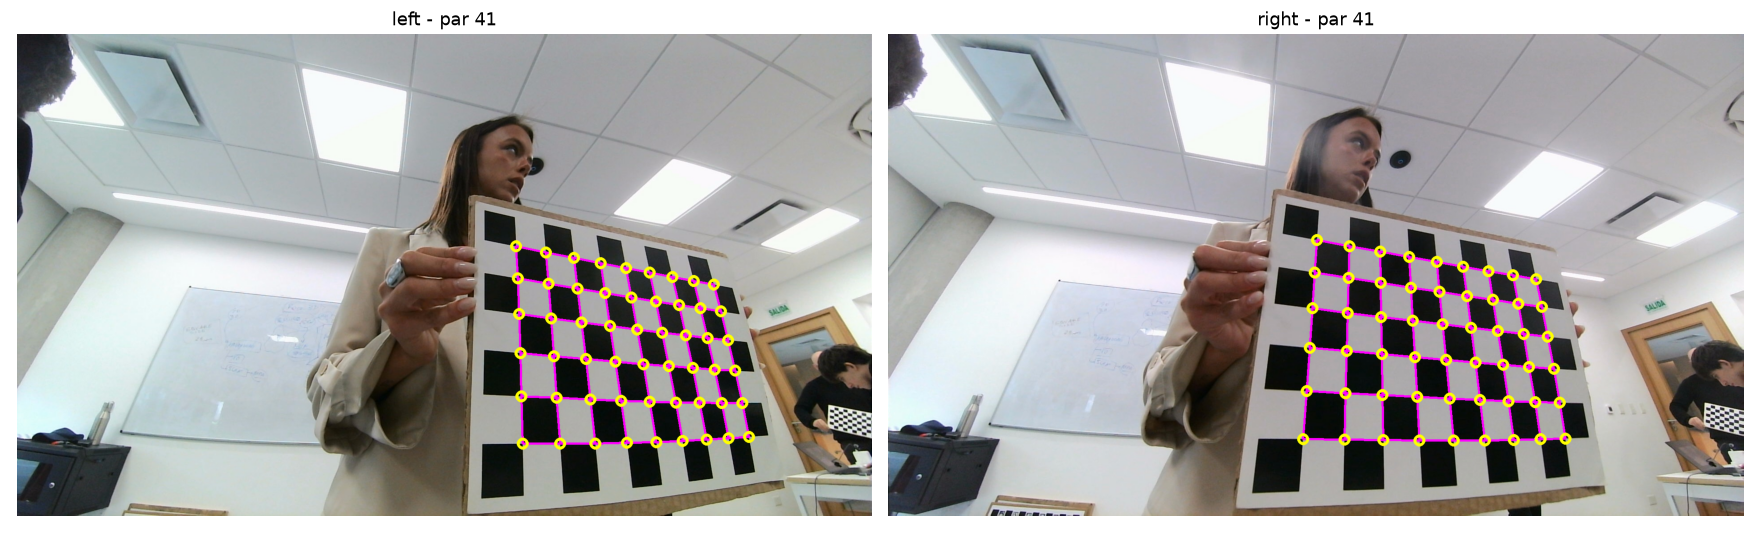

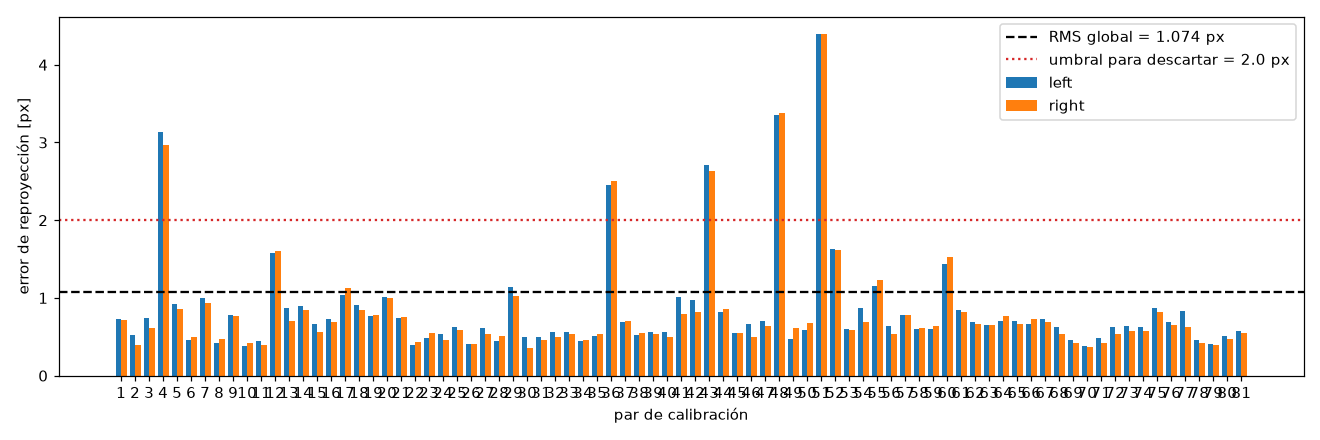

Pares descartados: [4, 36, 43, 48, 51]
RMS estéreo: 1.074 px con todos -> 0.711 px sin esos pares


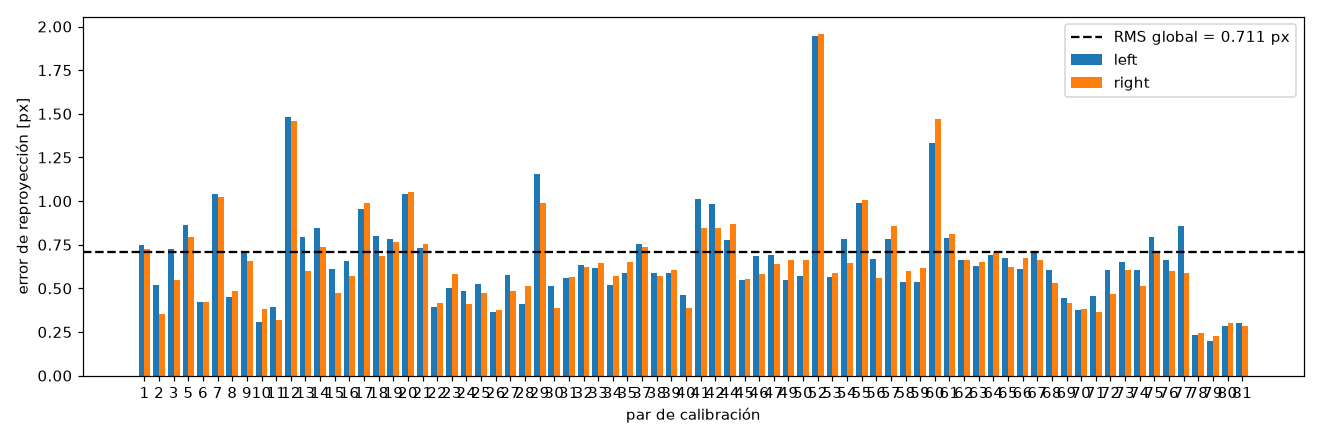

In [5]:
show_image(os.path.join(figures_dir, "00_deteccion_checkerboard.png"))

# error por par en la primera calibración (la línea roja es el umbral para descartar)
show_image(os.path.join(figures_dir, "00_error_por_vista.png"))

if stereo_params.get("dropped_pairs"):
    print(f"Pares descartados: {stereo_params['dropped_pairs']}")
    print(f"RMS estéreo: {stereo_params['rms_stereo_before_drop']:.3f} px con todos "
          f"-> {stereo_params['rms_stereo']:.3f} px sin esos pares")
    show_image(os.path.join(figures_dir, "00b_error_por_vista_final.png"))

**Qué nos dice la calibración.** Con los 81 pares, el RMS estéreo daba 1.07 px. En el primer
gráfico se ve que casi todos los pares están por debajo de 1 px, salvo 5 (el 4, 36, 43, 48 y 51)
que llegan a 2.5–4.4 px: seguramente fotos movidas o con el tablero muy inclinado. Sacando esos 5
y recalibrando, el **RMS baja a 0.71 px**, y en el segundo gráfico ya ningún par pasa de 2 px.

Los parámetros tienen sentido físico:

- f ≈ 605 px en las dos cámaras, y el centro óptico cerca del centro de la imagen (≈ 950, 540).
- R es casi la identidad (las cámaras están casi paralelas, con ~1° de giro) y T está casi
  toda en X, que es lo esperable para dos cámaras puestas una al lado de la otra.
- El baseline da **60.1 mm** (con todos los pares daba 60.7 mm).

Original vs. rectificada: después de rectificar, un mismo punto de la escena queda en la
**misma fila** en las dos imágenes (las líneas verdes ayudan a comprobarlo).

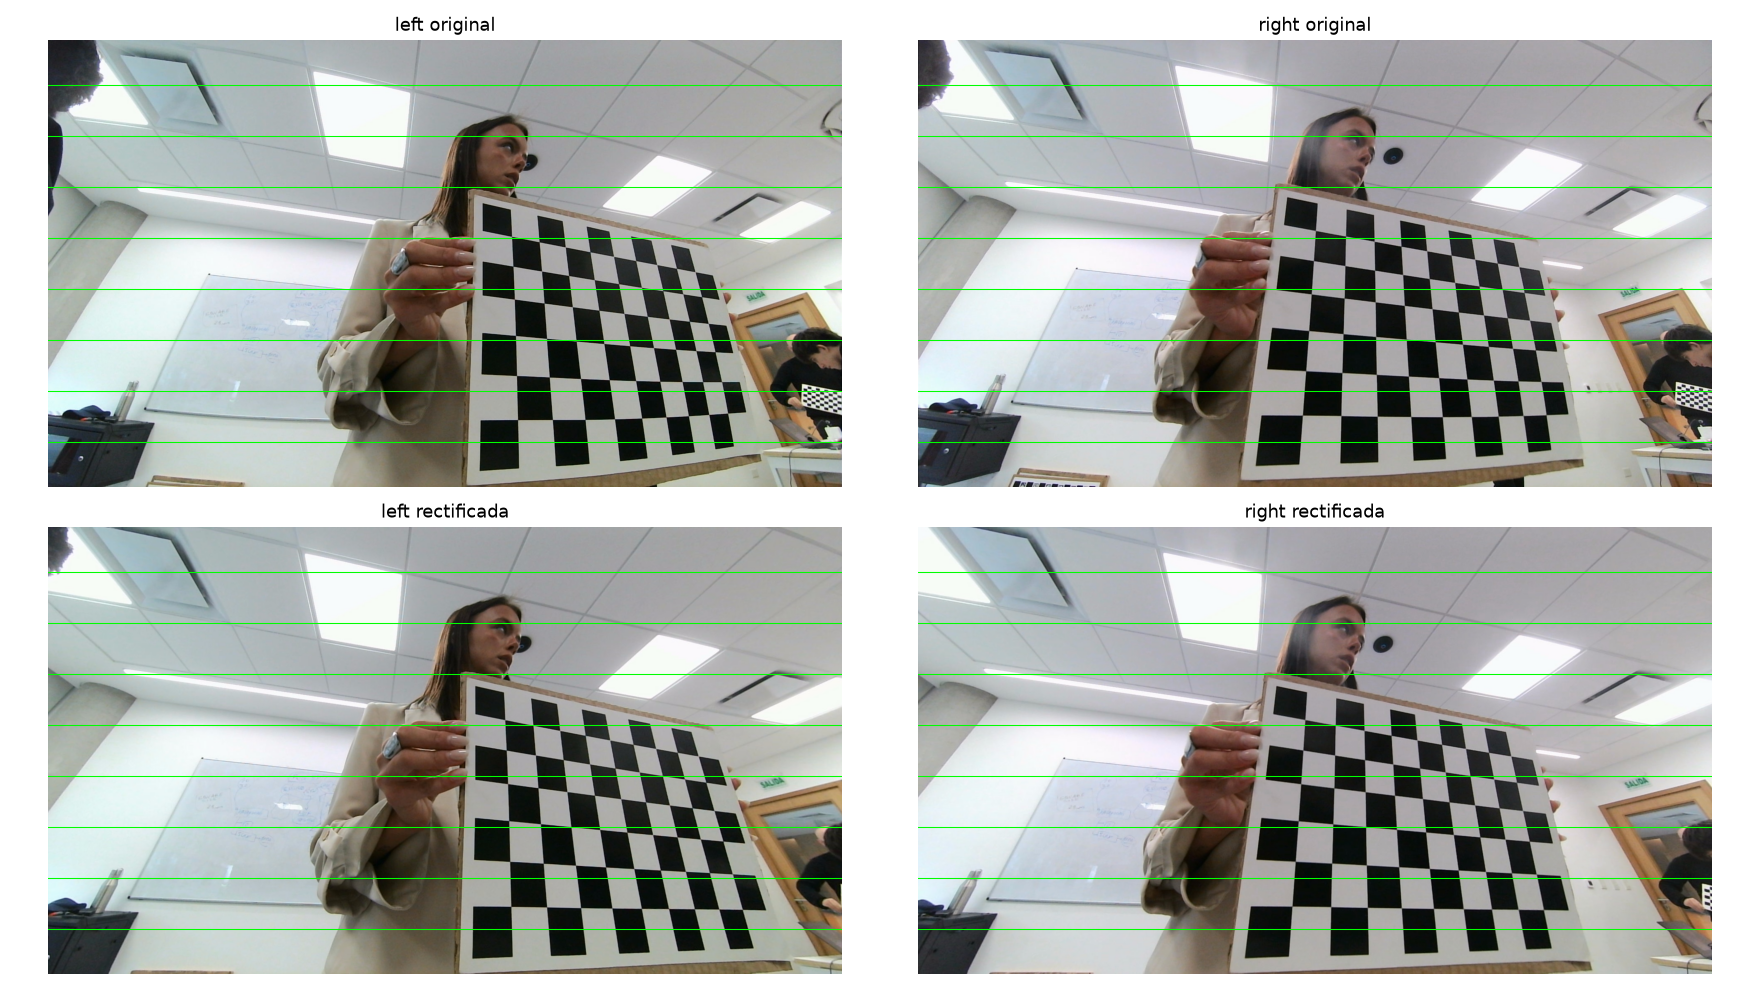

In [6]:
show_image(os.path.join(figures_dir, "01_rectificacion_calib.png"))

**Qué vemos.** Antes de rectificar, una misma esquina del tablero no cae exactamente sobre la
misma línea verde en las dos imágenes (los centros ópticos de las cámaras están a alturas
distintas: cy ≈ 540 vs. 529 px). Después de rectificar sí queda en la misma fila. Eso es lo que
buscábamos: ahora el correspondiente de cada píxel se busca solo a lo largo de su fila (búsqueda
1D), no en toda la imagen. Con `alpha=0` la imagen se recorta un poco en los bordes para que no
queden zonas negras.

## 2. Disparidad y nube local (una captura en detalle)

Sobre el par rectificado buscamos, para cada píxel de la imagen izquierda, el mismo punto en
la misma fila de la derecha. Cuánto se corrió en x es la disparidad `d`, y la profundidad sale
de `Z = f·B / d`: los objetos cercanos se corren mucho y los lejanos casi nada.
`reprojectImageTo3D` hace esa cuenta con la matriz `Q` de `stereoRectify` y devuelve (X, Y, Z)
en mm, en el sistema de la cámara izquierda rectificada.

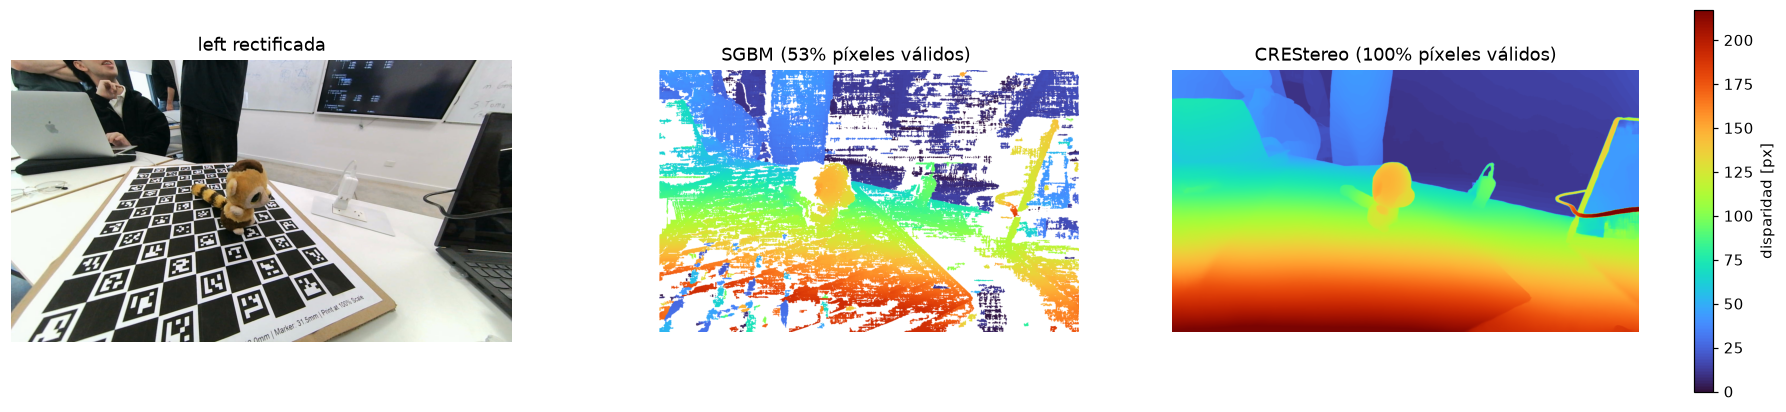

In [7]:
captures_dir = os.path.join(dataset_dir, "captures")
capture_pairs = list_stereo_pairs(captures_dir)
capture_id, left_path, right_path = capture_pairs[0]   # usamos la primera captura como ejemplo

left_img, right_img = cv2.imread(left_path), cv2.imread(right_path)
left_rect, right_rect = calibration.rectify_pair(left_img, right_img, rectify_maps)

disparity = run_pipeline.compute_disparity(config, left_rect, right_rect, capture_id, cache_dir)

if USE_CRESTEREO:
    # SGBM es rápido, así que lo calculamos igual para comparar los dos métodos.
    sgbm_disparity = stereo.compute_disparity(cv2.cvtColor(left_rect, cv2.COLOR_BGR2GRAY),
                                              cv2.cvtColor(right_rect, cv2.COLOR_BGR2GRAY), config.get("sgbm"))
    figure_path = os.path.join(figures_dir, "03b_sgbm_vs_crestereo.png")
    run_pipeline.save_disparity_comparison(left_rect, sgbm_disparity, disparity, figure_path)
    show_image(figure_path, width=1100)
else:
    figure_path = os.path.join(figures_dir, "03_disparidad.png")
    run_pipeline.save_disparity_figure(left_rect, disparity, figure_path, "disparidad SGBM [px]")
    show_image(figure_path)

**SGBM vs. CREStereo.** SGBM encuentra disparidad solo en algo más de la mitad de los píxeles.
Falla en la pared blanca, en la mesa y en partes del tablero, donde hay poca textura o un patrón
que se repite. CREStereo da un valor en todos los píxeles, con un mapa mucho más suave, y se
distingue bien el peluche (más cerca, colores cálidos) del fondo (azul). Por eso usamos CREStereo.

Ojo: "100 % válidos" no quiere decir 100 % correctos. En las zonas que ve una sola cámara
(bordes y oclusiones) la red igual pone un valor. Esos puntos los limpiamos después con el
rango de profundidad (`z_range`) y con la caja del objeto.

Nube local de la captura 0: 1,462,605 puntos


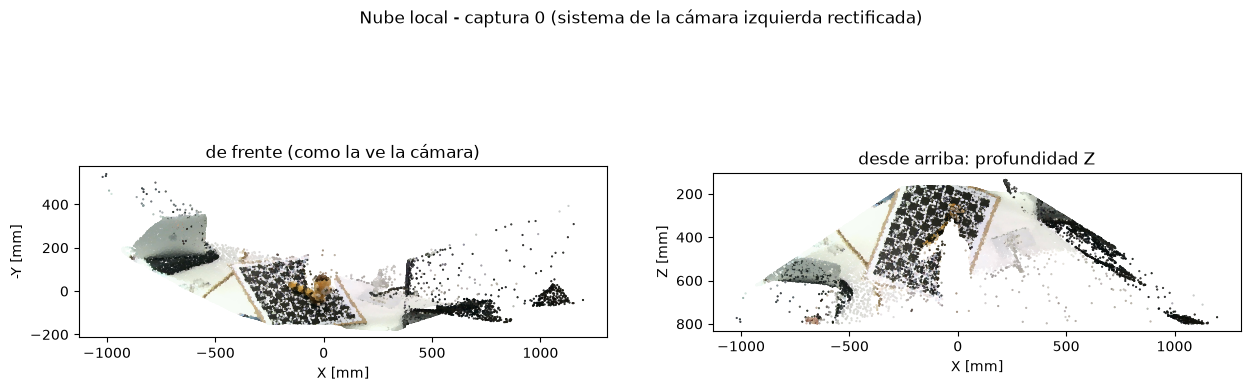

In [8]:
Q = rectify_maps["Q"]
local_points, local_colors = stereo.disparity_to_points(disparity, Q, left_rect, z_range=config["z_range"])
print(f"Nube local de la captura {capture_id}: {len(local_points):,} puntos")

# Dos vistas 2D de la nube, solo con lo que está cerca de la cámara (Z < 800 mm).
is_close = local_points[:, 2] < 800
close_points, close_colors = local_points[is_close], local_colors[is_close]
sample = np.random.default_rng(0).choice(len(close_points), min(60_000, len(close_points)), replace=False)
x, y, z = close_points[sample].T
colors = close_colors[sample]

fig, (ax_front, ax_top) = plt.subplots(1, 2, figsize=(15, 5))
ax_front.scatter(x, -y, c=colors, s=0.3)
ax_front.set_title("de frente (como la ve la cámara)"); ax_front.set_xlabel("X [mm]"); ax_front.set_ylabel("-Y [mm]")
ax_top.scatter(x, z, c=colors, s=0.3)
ax_top.set_title("desde arriba: profundidad Z"); ax_top.set_xlabel("X [mm]"); ax_top.set_ylabel("Z [mm]")
ax_top.invert_yaxis()
for ax in (ax_front, ax_top):
    ax.set_aspect("equal")
fig.suptitle(f"Nube local - captura {capture_id} (sistema de la cámara izquierda rectificada)")
plt.show()

**Qué vemos.** La nube de una sola captura ya tiene ~1.5 millones de puntos y muestra la
escena entera: el tablero, el peluche encima y parte de la mesa. Desde arriba el tablero se ve
como una superficie continua, sin escalones, así que la disparidad es coherente dentro de la
imagen. Los puntos sueltos de los costados (|X| > 500 mm) son fondo y bordes: los saca la caja
del objeto más adelante.

## 3. Pose con el ChArUco y paso al sistema del mundo

- Detectamos los marcadores ArUco e interpolamos las esquinas del ChArUco. De cada esquina
  sabemos dónde está en el tablero (en mm), así que tenemos pares punto 3D ↔ píxel.
- Con esos pares, `solvePnP` (método IPPE, pensado para patrones planos) devuelve `rvec, tvec`:
  la transformación **mundo → cámara**, `X_cam = R·X_world + t`. `rvec` es el **vector de
  Rodrigues**: su dirección es el eje de giro y su largo el ángulo. `cv2.Rodrigues` lo
  convierte en la matriz R.
- Para llevar la nube local al mundo usamos la transformación inversa: `X_world = Rᵀ·(X_cam − t)`.
- La pose la estimamos sobre la imagen izquierda **rectificada**, con `K = P1[:, :3]` y sin
  distorsión. Es el mismo sistema en el que `reprojectImageTo3D` da los puntos, así que las
  dos cosas encajan sin conversiones extra.

rvec (Rodrigues): [-1.014 -0.204 -0.271] -> giro de 61.3°
R =
 [[ 0.948  0.317 -0.043]
 [-0.128  0.5    0.856]
 [ 0.293 -0.806  0.514]]
t (mm) = [-384.2 -102.1  553. ]
Error de reproyección de PnP: 2.16 px con 177 esquinas


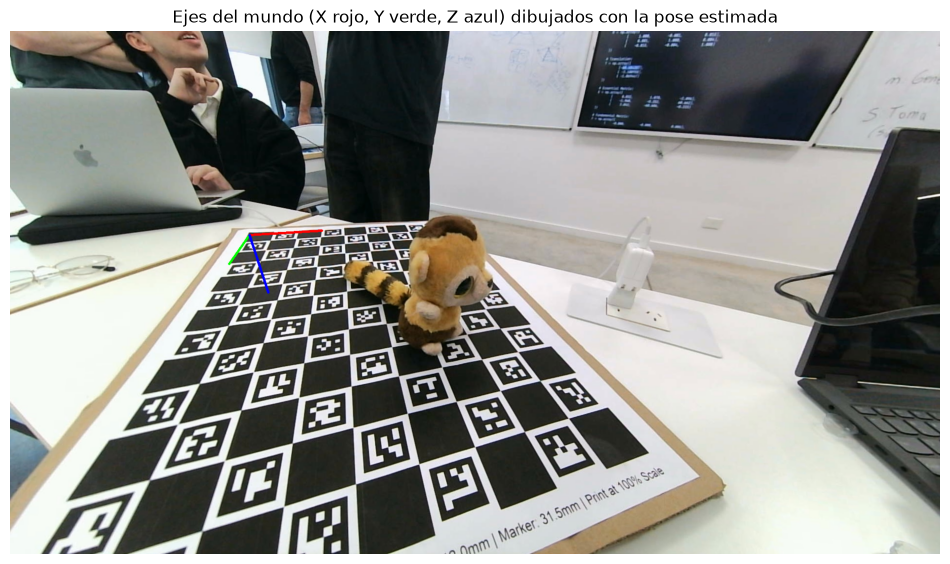

In [9]:
markers = read_markers_yaml(os.path.join(captures_dir, "markers.yaml"))
board = pose.make_charuco_board(markers) if markers["type"] == "charuco" else None
K_rect = rectify_maps["P1"][:, :3]   # intrínsecos de la cámara izquierda ya rectificada

board_pose = pose.estimate_pose(left_rect, markers, K_rect, board=board)
rvec, tvec = board_pose["rvec"], board_pose["tvec"]
R, _ = cv2.Rodrigues(rvec)
print("rvec (Rodrigues):", rvec.ravel().round(3), f"-> giro de {np.degrees(np.linalg.norm(rvec)):.1f}°")
print("R =\n", R.round(3))
print("t (mm) =", tvec.ravel().round(1))
print(f"Error de reproyección de PnP: {board_pose['reproj_error']:.2f} px con {board_pose['num_points']} esquinas")

square_mm = markers.get("square_length") or markers.get("square_size")
image_with_axes = pose.draw_pose(left_rect, rvec, tvec, K_rect, axis_len=3 * square_mm)
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(image_with_axes, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Ejes del mundo (X rojo, Y verde, Z azul) dibujados con la pose estimada")
plt.show()

### Corrección de la disparidad con el tablero

Con la pose ya sabemos a qué distancia está cada esquina del ChArUco, y por lo tanto qué
disparidad *debería* tener (`d = f·B / Z`). Si la comparamos con la que midió CREStereo en ese
mismo píxel, vemos si la disparidad de esta vista está corrida. Ajustamos una recta
`d_medida = a · d_esperada + b` y después corregimos todo el mapa con `d = (d_medida − b) / a`.

Hace falta en nuestro dataset porque cada captura tiene un error de profundidad distinto (más
abajo, en la sección 4, se ve qué pasa si no se corrige).

Ajuste con 166 esquinas: d_medida = 0.997 · d_esperada -2.56 px


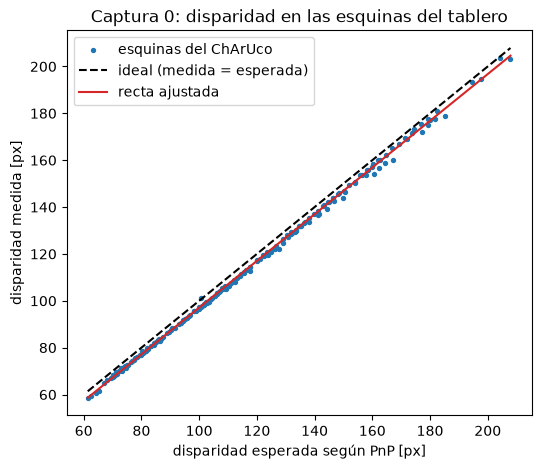

In [10]:
correction = stereo.board_disparity_correction(
    disparity, Q, board_pose["object_points"], board_pose["image_points"], rvec, tvec)

if correction is None:
    print("No se pudo ajustar la corrección en esta captura: se usa la disparidad tal cual.")
    corrected_disparity = disparity
else:
    scale, offset, corners_used = correction
    print(f"Ajuste con {corners_used} esquinas: d_medida = {scale:.3f} · d_esperada {offset:+.2f} px")
    corrected_disparity = stereo.apply_disparity_correction(disparity, scale, offset)

    # disparidad esperada (según PnP) vs. medida (CREStereo) en cada esquina del tablero
    corners_cam = board_pose["object_points"] @ R.T + tvec.reshape(3)
    expected = (Q[2, 3] / corners_cam[:, 2] - Q[3, 3]) / Q[3, 2]
    u, v = board_pose["image_points"].round().astype(int).T
    measured = disparity[v, u]
    ends = np.array([expected.min(), expected.max()])

    plt.figure(figsize=(6, 5))
    plt.scatter(expected, measured, s=8, label="esquinas del ChArUco")
    plt.plot(ends, ends, "k--", label="ideal (medida = esperada)")
    plt.plot(ends, scale * ends + offset, "tab:red", label="recta ajustada")
    plt.xlabel("disparidad esperada según PnP [px]"); plt.ylabel("disparidad medida [px]")
    plt.title(f"Captura {capture_id}: disparidad en las esquinas del tablero")
    plt.legend(); plt.show()

# la nube local de acá en adelante sale de la disparidad corregida
local_points, local_colors = stereo.disparity_to_points(corrected_disparity, Q, left_rect, z_range=config["z_range"])

Posición de la cámara en el mundo (mm): [ 189.2 -618.5  213.4]


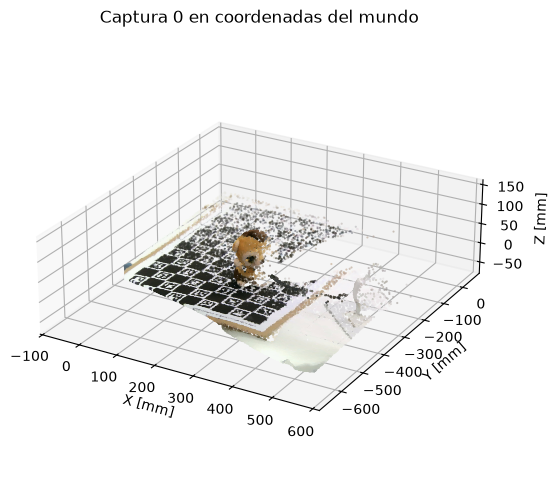

In [11]:
# Local -> mundo. FLIP_Z_UP gira 180° sobre X para que Z apunte hacia arriba desde el tablero.
T_world_from_cam = run_pipeline.FLIP_Z_UP @ pose.pose_to_matrix(rvec, tvec)
world_points = pose.transform_points(local_points, T_world_from_cam)
print("Posición de la cámara en el mundo (mm):", T_world_from_cam[:3, 3].round(1))

# Para el gráfico nos quedamos con lo que está cerca de la caja del objeto (±200 mm).
box_min, box_max = np.array(config["box_min"]), np.array(config["box_max"])
near_object = np.all((world_points > box_min - 200) & (world_points < box_max + 200), axis=1)
plot_cloud(world_points[near_object], local_colors[near_object], f"Captura {capture_id} en coordenadas del mundo")

**Qué vemos.**

- **Pose**: PnP da un error de reproyección de 2.16 px con 177 esquinas, y los ejes dibujados
  quedan justo en la esquina del tablero, alineados con sus bordes. El eje Z (azul) de OpenCV
  apunta *hacia adentro* del tablero; por eso aplicamos `FLIP_Z_UP`, para que en el mundo Z
  quede para arriba. El vector de Rodrigues indica un giro de ~61°, que tiene sentido porque la
  cámara mira el tablero bastante inclinada. La cámara queda a ~21 cm de altura.
- **Corrección**: los puntos caen casi sobre una recta, apenas por debajo de la ideal. En esta
  captura la disparidad medida está ~2.6 px por debajo de la esperada (escala 0.997). Parece
  poco, pero a 50 cm de distancia 2.6 px de disparidad son ~1.8 cm de profundidad. En otras
  capturas el corrimiento llega a −9 o +15 px.
- **Mundo**: en la nube pasada al mundo, el tablero queda horizontal en Z ≈ 0 y el peluche
  apoyado encima: la transformación local → mundo funciona.

## 4. Reconstrucción de todas las capturas

Repetimos lo mismo para cada par: disparidad → pose → corrección con el tablero → nube local →
mundo, y juntamos todo en una sola nube. Con CREStereo la primera corrida tarda ~15 min;
después usa las disparidades guardadas en `intermediate/`.

In [12]:
fused_cloud, camera_poses, per_capture, K_rect = run_pipeline.step_reconstruction(
    config, dataset_dir, rectify_maps, figures_dir, cache_dir)
print(f"\nNube fusionada: {len(fused_cloud.points):,} puntos de {len(camera_poses)} capturas")


[4.2] Disparidad, nube local y pose de cada captura
  objeto de referencia: {'type': 'charuco', 'dictionary': 'DICT_5X5_100', 'squares_x': 9, 'squares_y': 13, 'square_length': 42.0, 'marker_length': 31.5}
  captura  0: 1,517,335 pts | pose pnp (177 pts, err 2.16px) | cámara en [ 189. -618.  213.] | disp. corregida: x0.997 -2.6px
  captura  1: 1,125,102 pts | pose pnp (72 pts, err 2.57px) | cámara en [ 188. -607.  196.] | disp. corregida: x0.992 -3.3px
  captura  2: 1,476,872 pts | pose pnp (200 pts, err 3.10px) | cámara en [  74. -489.  249.] | disp. corregida: x0.980 -6.3px
  captura  3: 1,684,376 pts | pose pnp (246 pts, err 2.92px) | cámara en [  20. -406.  239.] | disp. corregida: x0.980 -6.4px
  captura  4: 1,523,389 pts | pose pnp (270 pts, err 2.22px) | cámara en [  12. -295.  294.] | disp. corregida: x0.982 -6.3px
  captura  5: 1,500,951 pts | pose pnp (258 pts, err 2.10px) | cámara en [  29. -223.  301.] | disp. corregida: x0.974 -5.1px
  captura  6: 1,509,273 pts | pose pnp 

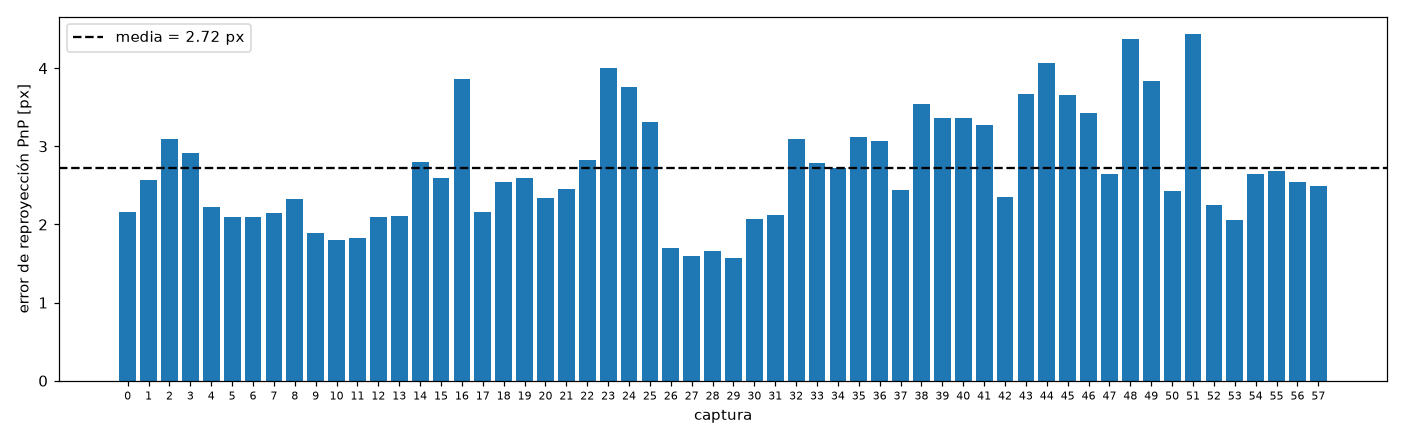

In [13]:
figure_path = os.path.join(figures_dir, "04b_error_pnp_por_captura.png")
run_pipeline.save_pnp_errors_figure(per_capture, figure_path)
show_image(figure_path)

**Qué vemos.** Se estimó la pose en las 58 capturas (ninguna se descartó) y la corrección de
disparidad se pudo ajustar en todas: escalas entre 0.91 y 1.09 y corrimientos entre −9 y +15 px.

El error de PnP va de 1.6 a 4.4 px, con promedio ~2.7 px. Es más alto que en el dataset del Buda
(0.9–1.8 px). Las capturas con más error (51, 48, 44, 23, 16) son las que se sacaron más bajas
(cámara a 9–17 cm del tablero), donde el tablero se ve muy en perspectiva y el peluche tapa
parte de los marcadores.

Poses de cámara estimadas (pirámides rojas) sobre la escena: tendrían que seguir el recorrido
que hicimos alrededor del objeto al sacar las fotos.

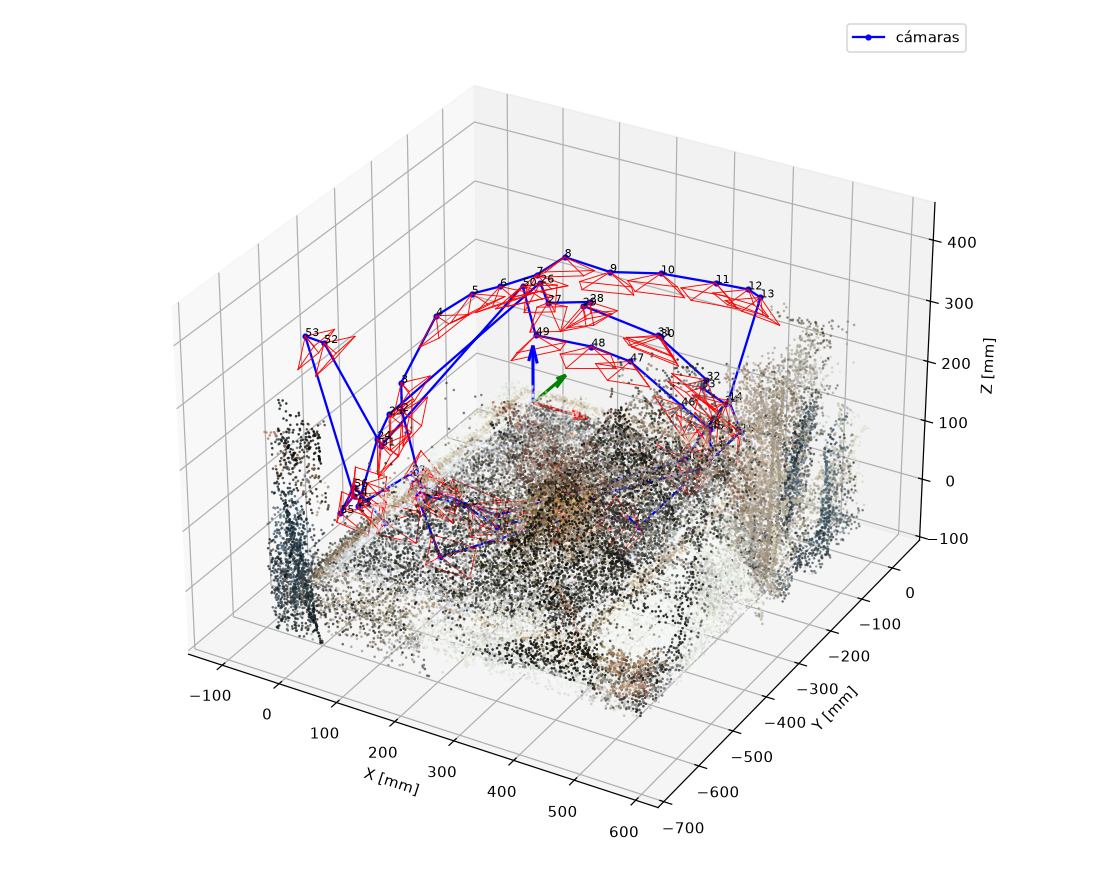

In [14]:
# Para el dibujo alcanza con una versión liviana de la escena (un punto cada 3 mm).
light_scene = fused_cloud.voxel_down_sample(3.0)
margin = np.array([200, 200, 50])
scene_near_object = light_scene.crop(o3d.geometry.AxisAlignedBoundingBox(box_min - margin, box_max + margin))

figure_path = os.path.join(figures_dir, "05_poses_camaras.png")
run_pipeline.save_poses_figure(scene_near_object, camera_poses, figure_path, K_rect, stereo_params["image_size"])
show_image(figure_path, width=800)

**Qué vemos.** Las cámaras dibujan una cúpula alrededor del peluche, entre ~9 y ~42 cm de
altura, y siempre mirando hacia el objeto. Coincide con cómo sacamos las fotos: dando vueltas
alrededor del tablero a distintas alturas. Las capturas 51 a 53 quedan del lado de X negativo,
más allá del borde del tablero. No aparecen poses "voladas" (cámaras debajo del tablero o
lejísimos), así que la detección del ChArUco fue confiable en todas las tomas.

### ¿Encajan bien las vistas entre sí?

Una forma simple de chequearlo: el tablero es el plano Z = 0 del mundo, así que en **cada**
captura los puntos del tablero tendrían que caer en Z ≈ 0. Medimos la altura del tablero
(mediana de Z) en una muestra de capturas, mirando solo la parte del tablero que queda fuera
de la caja del objeto, sin corregir la disparidad y corrigiéndola.

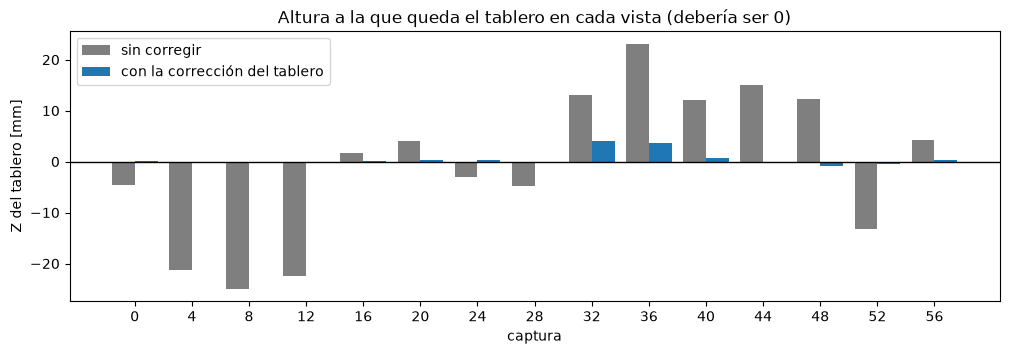

Sin corregir:  de -24.9 a 23.1 mm (desvío 14.3 mm)
Con corrección: de -0.9 a 4.1 mm (desvío 1.4 mm)


In [15]:
# Extensión del tablero en el mundo (mm): X de 0 a 9 cuadrados, Y de 0 a -13 cuadrados.
board_x = (0, markers["squares_x"] * square_mm)
board_y = (-markers["squares_y"] * square_mm, 0)


def board_height_in_view(disparity_map, left_image, T_world):
    """Mediana de Z de los puntos del tablero (fuera de la caja del objeto) en una vista."""
    points, _ = stereo.disparity_to_points(disparity_map, Q, left_image, z_range=config["z_range"])
    world = pose.transform_points(points, T_world)
    x, y, z = world.T
    on_board = (x > board_x[0]) & (x < board_x[1]) & (y > board_y[0]) & (y < board_y[1]) & (np.abs(z) < 60)
    inside_object_box = np.all((world > box_min) & (world < box_max), axis=1)
    return np.median(z[on_board & ~inside_object_box])


heights_raw, heights_fixed, checked_ids = [], [], []
for capture_id_i, left_path_i, right_path_i in capture_pairs[::4]:   # una de cada 4 capturas
    left_i, right_i = calibration.rectify_pair(cv2.imread(left_path_i), cv2.imread(right_path_i), rectify_maps)
    disparity_i = run_pipeline.compute_disparity(config, left_i, right_i, capture_id_i, cache_dir)
    pose_i = pose.estimate_pose(left_i, markers, K_rect, board=board)
    if pose_i is None:
        continue
    T_i = run_pipeline.FLIP_Z_UP @ pose.pose_to_matrix(pose_i["rvec"], pose_i["tvec"])
    correction_i = stereo.board_disparity_correction(
        disparity_i, Q, pose_i["object_points"], pose_i["image_points"], pose_i["rvec"], pose_i["tvec"])
    fixed_i = stereo.apply_disparity_correction(disparity_i, *correction_i[:2]) if correction_i else disparity_i

    checked_ids.append(str(capture_id_i))
    heights_raw.append(board_height_in_view(disparity_i, left_i, T_i))
    heights_fixed.append(board_height_in_view(fixed_i, left_i, T_i))

x = np.arange(len(checked_ids))
plt.figure(figsize=(12, 3.5))
plt.bar(x - 0.2, heights_raw, 0.4, color="tab:gray", label="sin corregir")
plt.bar(x + 0.2, heights_fixed, 0.4, color="tab:blue", label="con la corrección del tablero")
plt.axhline(0, color="k", lw=1)
plt.xticks(x, checked_ids)
plt.xlabel("captura"); plt.ylabel("Z del tablero [mm]")
plt.title("Altura a la que queda el tablero en cada vista (debería ser 0)")
plt.legend(); plt.show()
print(f"Sin corregir:  de {min(heights_raw):.1f} a {max(heights_raw):.1f} mm (desvío {np.std(heights_raw):.1f} mm)")
print(f"Con corrección: de {min(heights_fixed):.1f} a {max(heights_fixed):.1f} mm (desvío {np.std(heights_fixed):.1f} mm)")

**Qué vemos.** Sin corregir, el tablero queda entre **−25 y +23 mm** según la captura, y con un
patrón claro: en las tomas desde arriba (4 a 12, cámara a ~30 cm) queda ~20 mm por debajo de
cero, y en las tomas desde más abajo y de costado (32 a 48) queda 10–23 mm por encima. Que el
error dependa del punto de vista nos dice que no es ruido al azar: cada nube local tiene un
error de profundidad propio. Coincide con lo que encontramos revisando la rectificación (ver
README): entre las dos imágenes queda un corrimiento vertical de 1–4 px que cambia de una
captura a otra, probablemente porque movíamos la cámara en la mano al sacar las fotos.

Con la corrección del tablero, todas las vistas quedan entre **−1 y +4 mm** (el desvío baja
de 14.3 a 1.4 mm). O sea que ahora las nubes de las distintas capturas encajan entre sí.

## 5. Fusión y optimización

1. **Bounding box** (`OrientedBoundingBox` en coordenadas del mundo): nos quedamos solo con la
   zona del objeto.
2. **Voxel downsample**: un punto por voxel de 1 mm. Saca la redundancia de las vistas que se
   solapan y baja mucho el peso.
3. **Plano del tablero** (RANSAC, `segment_plane`): descartamos los puntos a menos de 15 mm del
   plano. Probamos márgenes más chicos (5, 8 y 10 mm) pero vuelven a aparecer restos del tablero.
4. **Statistical outlier removal**: saca los puntos sueltos que quedaron flotando.
5. **Cluster principal** (DBSCAN): nos quedamos con el grupo de puntos más grande, que es el objeto.

  plano RANSAC: n=[ 0.0249 -0.0031  0.9997], d=-6.93
       original: 99,740,257 puntos
   bounding_box: 13,116,181 puntos
          voxel:  1,186,735 puntos
  plane_removal:    417,145 puntos
       outliers:    388,504 puntos
        cluster:    358,309 puntos


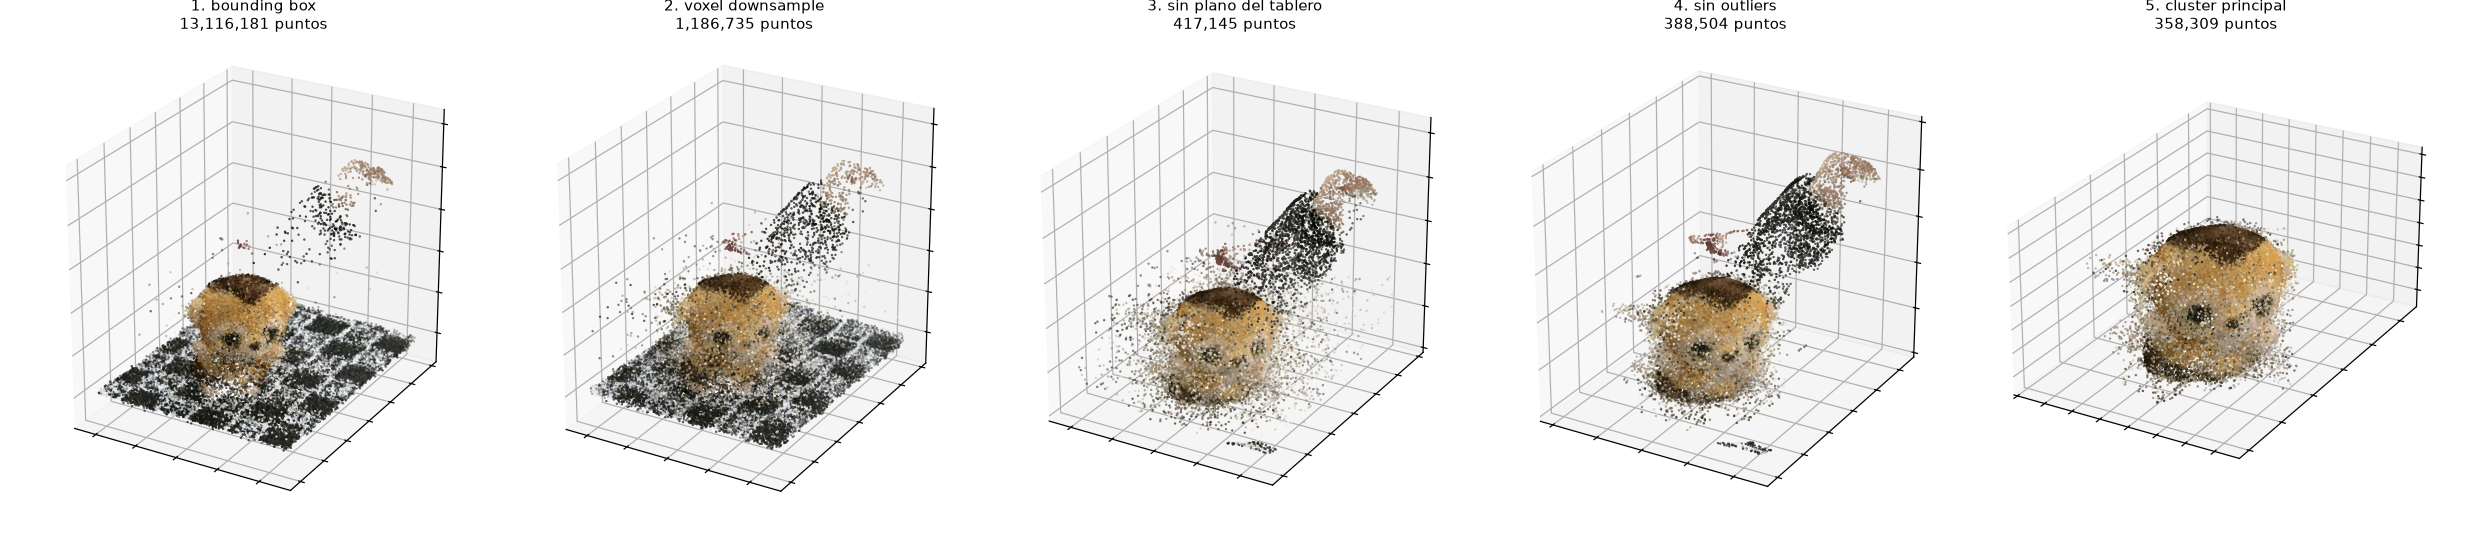

In [16]:
clouds_per_stage = {}
outlier_params = config["outliers"]
final_cloud, object_box, board_plane, points_per_stage = fusion.optimize(
    fused_cloud, config["box_min"], config["box_max"], config["voxel_size"],
    outlier_params["nb_neighbors"], outlier_params["std_ratio"], plane_margin=config.get("plane_margin"),
    clouds=clouds_per_stage,
)
if config.get("largest_cluster_eps"):
    final_cloud = fusion.keep_largest_cluster(final_cloud, config["largest_cluster_eps"])
    points_per_stage["largest_cluster"] = len(final_cloud.points)
    clouds_per_stage["largest_cluster"] = final_cloud
    print(f"  {'cluster':>13}: {points_per_stage['largest_cluster']:>10,} puntos")

figure_path = os.path.join(figures_dir, "06a_etapas_optimizacion.png")
run_pipeline.save_stages_figure(clouds_per_stage, figure_path)
show_image(figure_path, width=1200)

**Qué vemos.** Cuántos puntos quedan en cada etapa:

| etapa | puntos | qué se va |
|---|---|---|
| nube fusionada | 99.7 M | — |
| caja del objeto | 13.1 M | el 87 % era fondo, mesa y resto del tablero |
| voxel de 1 mm | 1.19 M | había ~11 puntos por voxel: muchas vistas ven lo mismo |
| sin plano del tablero | 0.42 M | el tablero |
| sin outliers | 0.39 M | ~7 %, puntos sueltos |
| cluster principal | 0.36 M | lo que flota arriba a la derecha y otros restos |

Como ahora las vistas encajan, después del voxel quedan la mitad de puntos que sin la
corrección (1.19 M contra 2.26 M): las mismas superficies vistas desde distintas capturas caen
en los mismos voxels en vez de formar capas separadas. El plano de RANSAC queda en Z ≈ 3 mm,
casi horizontal, y el tablero se va entero en ese paso. Lo que queda flotando arriba a la
derecha no es el peluche: es parte del fondo que entra en la caja, y lo saca el último paso (DBSCAN).

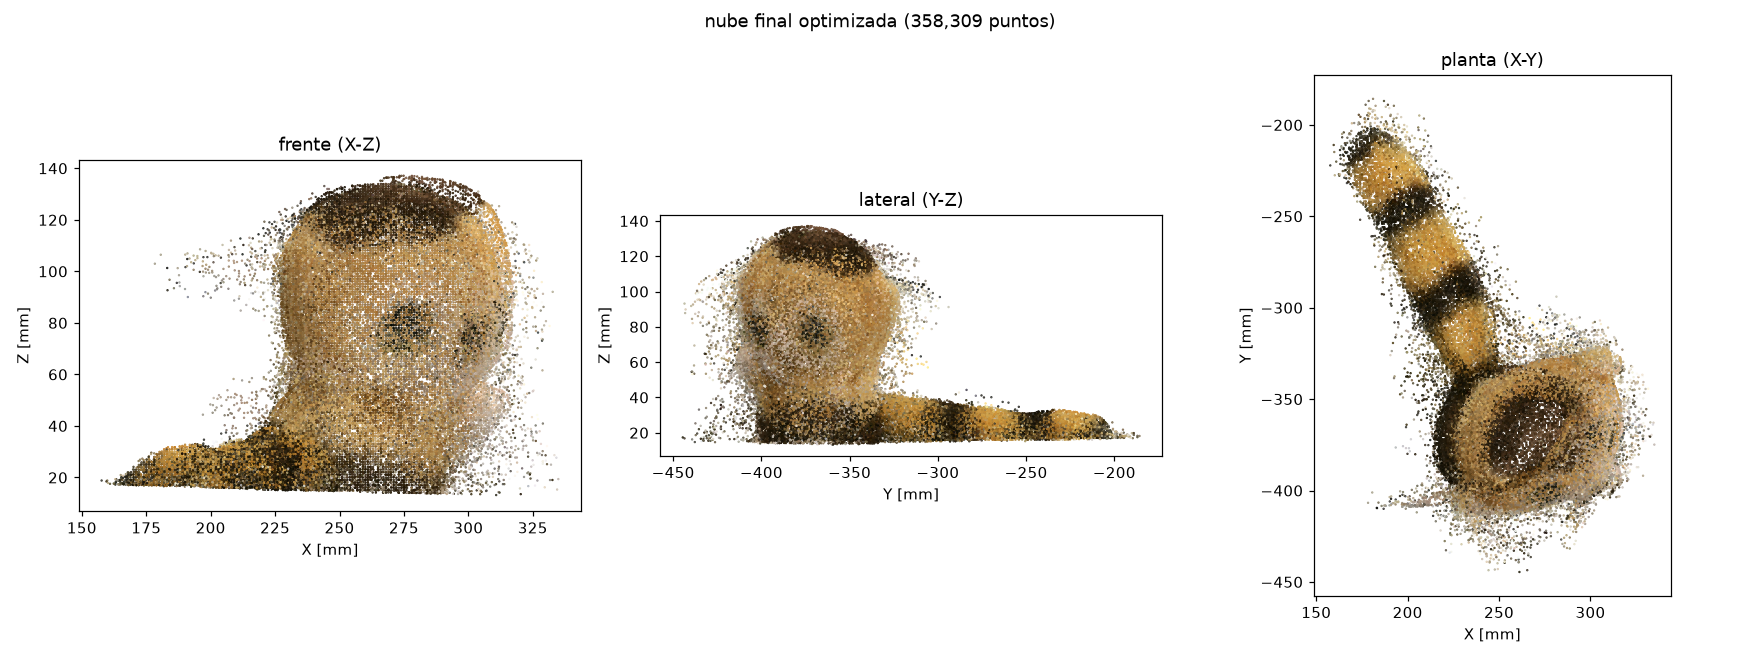

Guardado c:\Users\pepob\OneDrive\Documentos\Facu\Vision Artificial\tp2_reconstruccion_3d\output/grupo\reconstruction.ply (9.7 MB)


In [17]:
figure_path = os.path.join(figures_dir, "06_nube_final.png")
run_pipeline.save_cloud_views(final_cloud, figure_path, "nube final optimizada")
show_image(figure_path, width=1200)

ply_path = os.path.join(output_dir, "reconstruction.ply")
o3d.io.write_point_cloud(ply_path, final_cloud, write_ascii=False)   # .ply binario, como pide el enunciado
print(f"Guardado {ply_path} ({os.path.getsize(ply_path) / 1e6:.1f} MB)")

**Qué vemos.** Se reconoce bien el peluche: la cabeza con los ojos, el cuerpo y la cola rayada
apoyada sobre el tablero, y ya no quedan restos del tablero alrededor. Como cortamos 15 mm sobre
el plano, la parte más baja del peluche (la que toca el tablero) no está en la nube.

El `.ply` final pesa ~10 MB, en el orden de las "decenas de MB" que pide el enunciado. Es la
mitad que sin la corrección porque hay menos puntos duplicados.

Visor interactivo (se puede rotar con el mouse). Anda en Colab y en Jupyter si está
instalado `plotly`.

In [18]:
SHOW_3D = COLAB   # en local, poner True para verlo (agrega varios MB al notebook)
if SHOW_3D:
    o3d.visualization.draw_plotly([final_cloud.voxel_down_sample(3.0)])

## 6. Malla con Poisson (opcional)

Estimamos normales con los vecinos de cada punto → reconstrucción de Poisson → sacamos los
vértices con poca densidad (superficie que Poisson "inventa" donde no hay datos) → simplificamos
la malla para que pese poco.

199,999 triángulos -> c:\Users\pepob\OneDrive\Documentos\Facu\Vision Artificial\tp2_reconstruccion_3d\output/grupo\reconstruction_mesh.ply


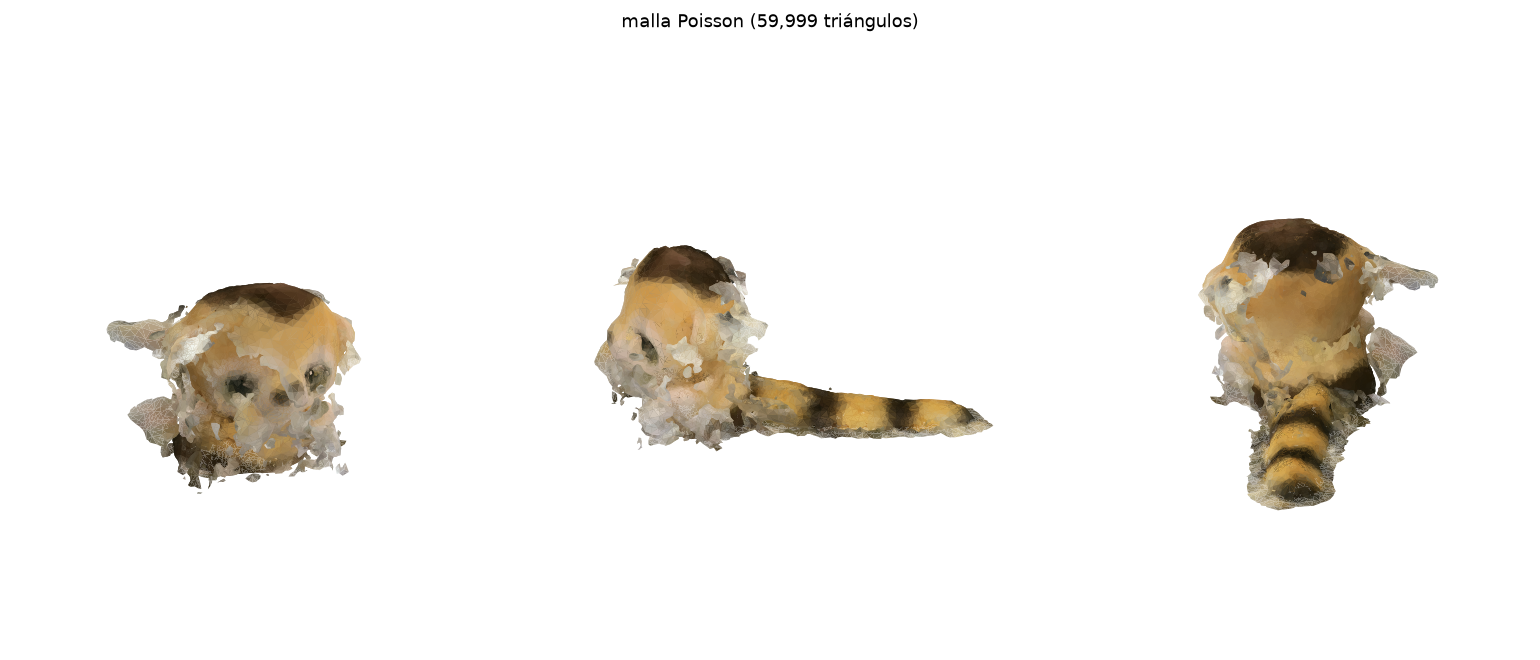

In [19]:
poisson_params = config.get("poisson") or {}
mesh = fusion.poisson_mesh(final_cloud, depth=poisson_params.get("depth", 8),
                           normal_radius=poisson_params.get("normal_radius", 5.0),
                           density_quantile=poisson_params.get("density_quantile", 0.05),
                           target_triangles=poisson_params.get("target_triangles", 200_000))
mesh_path = os.path.join(output_dir, "reconstruction_mesh.ply")
o3d.io.write_triangle_mesh(mesh_path, mesh)
print(f"{len(mesh.triangles):,} triángulos -> {mesh_path}")

figure_path = os.path.join(figures_dir, "07_malla_poisson.png")
run_pipeline.save_mesh_figure(mesh, figure_path)
show_image(figure_path, width=1200)

**Qué vemos.** La malla cierra bien la superficie del peluche y le da una forma más fácil de
leer que la nube. La cola y la parte de atrás quedan bastante limpias; en la cara y a los
costados aparecen algunas "aletas" claras, que es superficie que Poisson extrapola donde hay
pocos puntos (probablemente zonas que casi no se ven en ninguna foto, como debajo de la cabeza). Ya no aparece
la "alfombra" del tablero debajo del objeto.

## 7. Medición métrica

La reconstrucción queda en **milímetros**, sin la ambigüedad de escala de otros métodos, porque:
- el **baseline** sale de la calibración estéreo, que se hizo con un checkerboard de tamaño
  conocido, y la profundidad se calcula con `Z = f·B/d`;
- la pose se estima contra el ChArUco, cuyas medidas también conocemos.

Alto = distancia al plano del tablero (percentil 99.5, para no depender de un único punto espurio).
Ancho y profundidad = extensión en X e Y (entre los percentiles 0.5 y 99.5).

In [20]:
measures = fusion.measure(final_cloud, board_plane)
print(f"Alto (sobre el plano de apoyo): {measures['height_mm']:.1f} mm  (máximo {measures['height_max_mm']:.1f} mm)")
print(f"Ancho X: {measures['width_x_mm']:.1f} mm | profundidad Y: {measures['depth_y_mm']:.1f} mm")

if config.get("real_height_mm"):
    relative_error = abs(measures["height_mm"] - config["real_height_mm"]) / config["real_height_mm"]
    print(f"Alto real: {config['real_height_mm']} mm -> error relativo {relative_error:.1%}")

Alto (sobre el plano de apoyo): 133.4 mm  (máximo 138.3 mm)
Ancho X: 143.2 mm | profundidad Y: 211.2 mm


**Qué tan confiable es la medición.**

- **Alto ≈ 133 mm** sobre el plano del tablero. Ahora la referencia es buena: las vistas
  coinciden en la altura del tablero con ±2 mm, así que el error de esta medida debería ser de
  unos pocos milímetros.
- **Ancho X ≈ 144 mm y profundidad Y ≈ 212 mm.** Ahora sí son del peluche (antes daban 217 y
  259 mm porque los inflaban los restos del tablero). La profundidad incluye la cola, que está
  estirada hacia atrás sobre el tablero.
- No medimos el peluche con regla (`real_height_mm: null`), así que no podemos calcular el error
  relativo que pide el enunciado. Para hacerlo alcanza con medirlo y cargar el valor en la config:
  esta celda calcula el error sola.

## Resumen

- **Calibración**: RMS 0.71 px (descartando 5 pares malos), baseline 60.1 mm.
- **Disparidad y pose**: CREStereo y ChArUco en las 58 capturas, con error de PnP promedio de 2.7 px.
- **Vistas**: cada captura tenía un error de profundidad propio (el tablero quedaba entre −25 y
  +23 mm). Lo corregimos usando el ChArUco como referencia, y ahora quedan entre −1 y +4 mm.
- **Nube final**: 0.36 M puntos, ~10 MB, sin restos del tablero.
- **Medición**: alto ≈ 133 mm, ancho ≈ 144 mm, profundidad ≈ 212 mm (con la cola).

Lo que queda pendiente o se podría mejorar:

- Medir el peluche con regla para tener el error relativo.
- Sacar las fotos con la cámara apoyada y quieta: así no haría falta corregir cada vista.
- Alinear las vistas con ICP (opcional del enunciado) para afinar lo que la corrección no llega a
  arreglar, por ejemplo los bordes de la cara, que todavía se ven algo borrosos.